# Noise, mechanisms and confounders


Compares linear/mixed mechanisms, noise distributions and observed/latent confounding. Complete-fit coverage is required for paired condition comparisons.


In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark")
sources = th.load_aligned_sources()
benchmark_data = sources["benchmark_data"]


## Mechanisms and noise


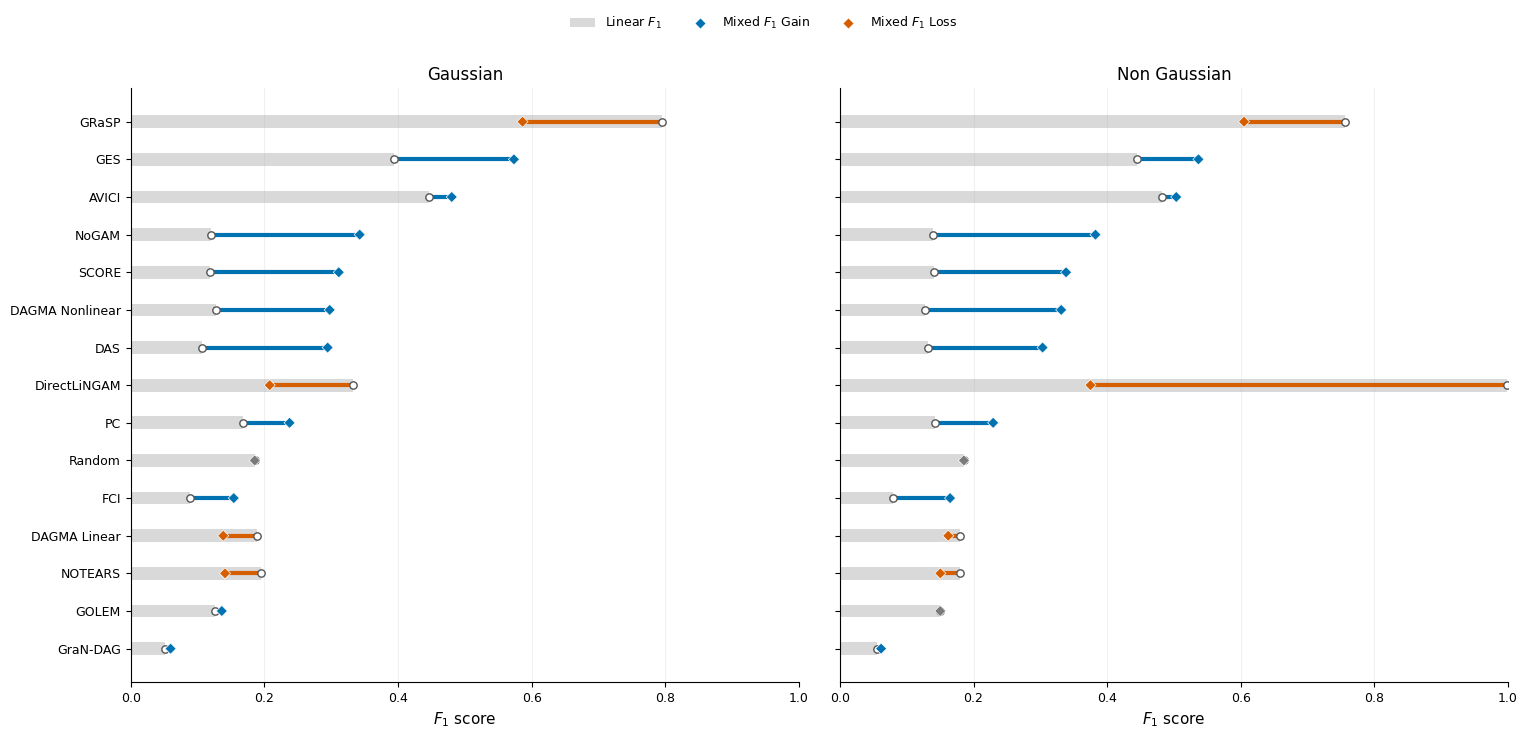

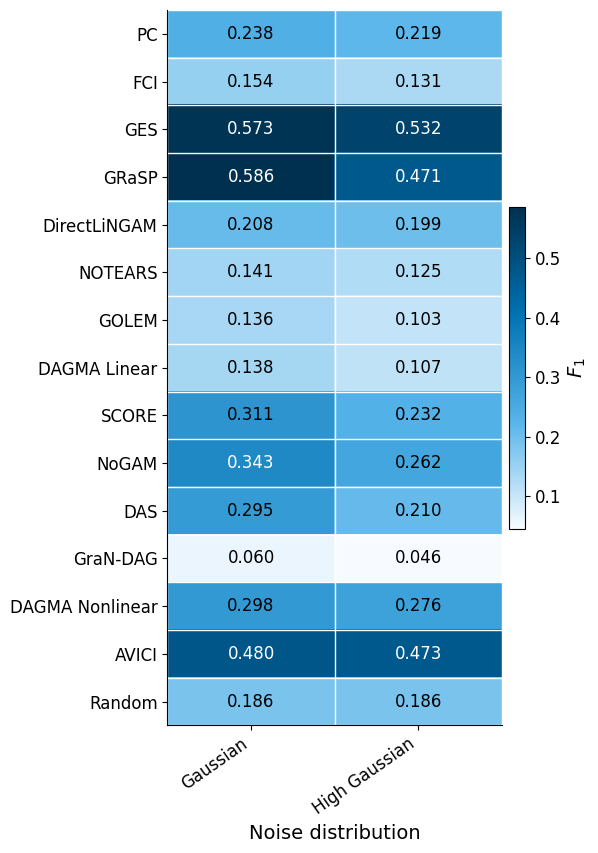

In [2]:
_, _, mechanism_tables = fv.plot_mechanism_heatmap(
    benchmark_data,
    metric="f1",
    mechanisms=("Linear", "Mixed"),
    noises={
        "Gaussian": ("Gaussian",),
        "Non Gaussian": ("NonGaussian", "Non_Gaussian"),
    },
    n_nodes=20,
    graph_type="EB",
    obs_conf=0,
    lat_conf=0,
    coverage_policy="complete",
    show_metric_title=False,
)
plt.close(plt.gcf())
fig_mechanism, _, mechanism_change = fv.plot_mechanism_change_bars(
    mechanism_tables,
    baseline="Linear",
    comparison="Mixed",
    order_by="comparison",
    xlim=(0, 1),
    annotate_delta=False,
    xlabel="$F_1$ score",
    show_title=False,
    figsize=(15.5, 7.5),
    font_size=11,
    title_size=12,
)
mechanism_pdf = th.save_pdf(fig_mechanism, "Mechanism_change_F1.pdf")
display(fig_mechanism)
plt.close(fig_mechanism)
_, _, high_noise_table = fv.plot_noise_heatmap(
    benchmark_data,
    metric="f1",
    noises={"Gaussian": ("Gaussian",), "High Gaussian": ("HighGaussian",)},
    mechanisms=("Mixed",),
    n_nodes=20,
    graph_type="EB",
    obs_conf=0,
    lat_conf=0,
    coverage_policy="complete",
    show_metric_title=False,
)


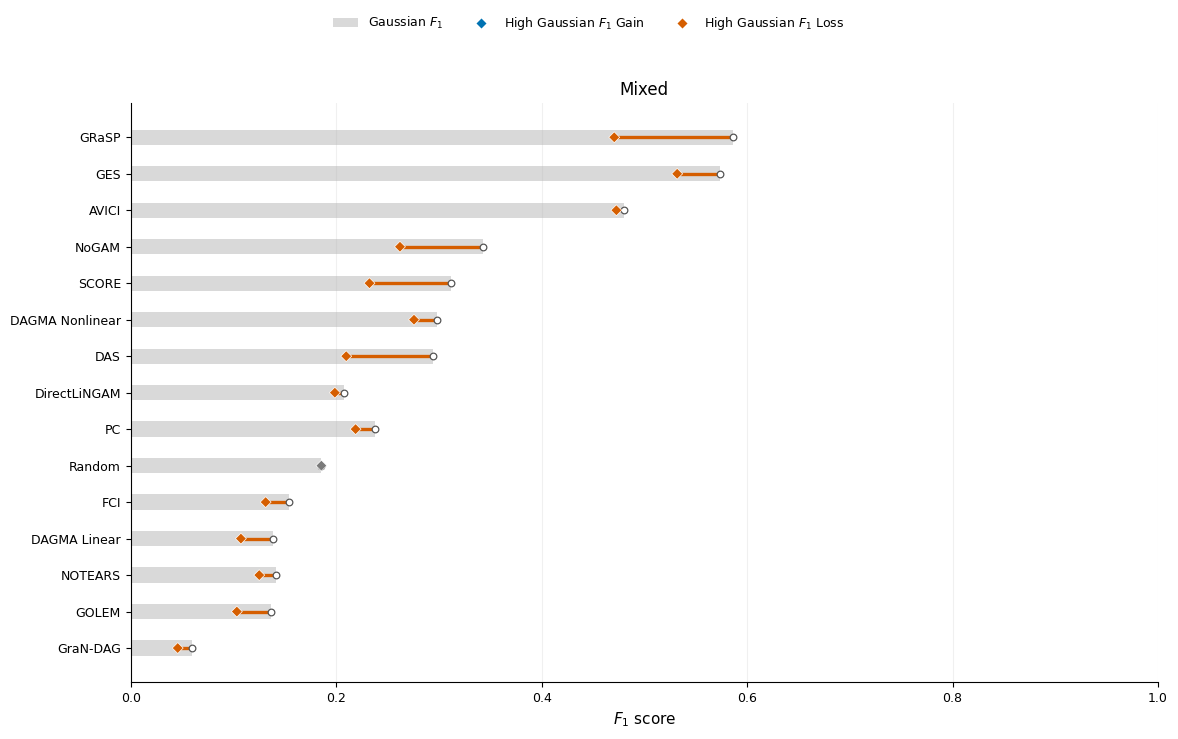

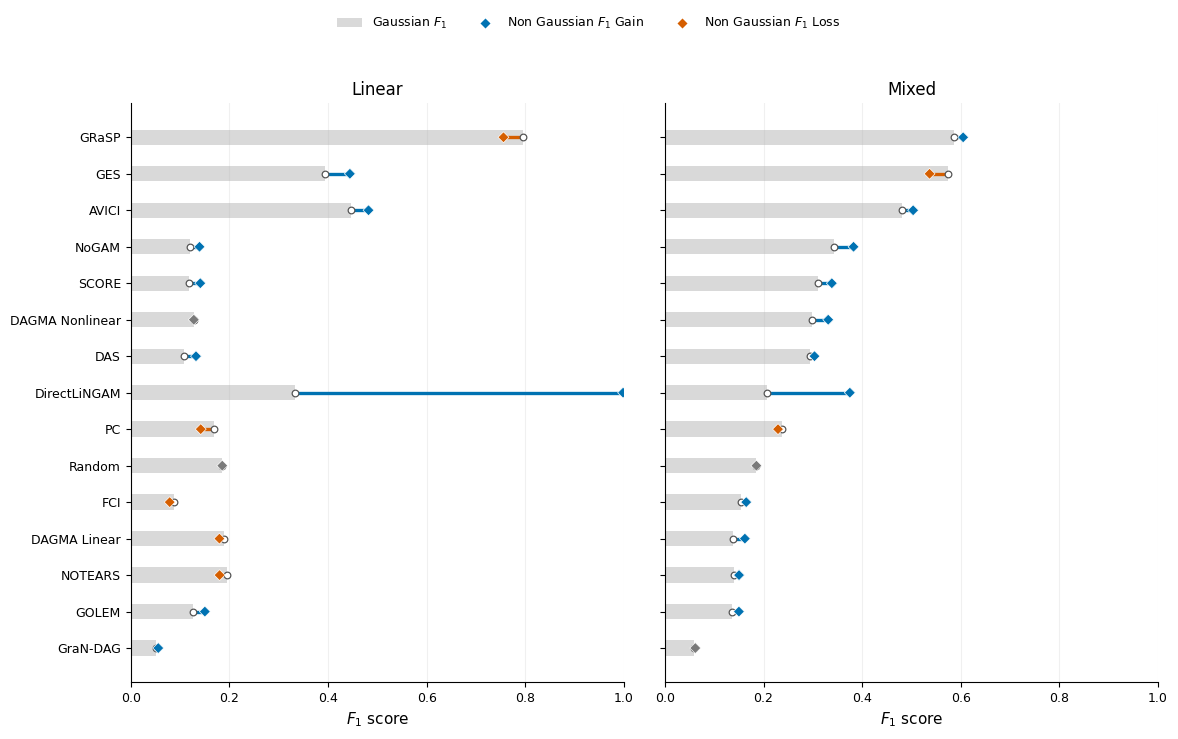

In [3]:
plt.close(plt.gcf())
shared_noise_model_order = mechanism_change["model_order"]["model"].tolist()
fig_high, _, high_change = fv.plot_noise_change_by_mechanism(
    {"Mixed": high_noise_table},
    baseline="Gaussian",
    comparisons=("High Gaussian",),
    model_order=shared_noise_model_order,
    xlim=(0, 1),
    xlabel="$F_1$ score",
    show_title=False,
    figsize=(12.0, 7.5),
    font_size=11,
    title_size=12,
)
high_pdf = th.save_pdf(fig_high, "Noise_change_HighGaussian_F1.pdf")
display(fig_high)
plt.close(fig_high)
noise_by_mechanism = {}
for mechanism in ("Linear", "Mixed"):
    _, _, output = fv.plot_noise_heatmap(
        benchmark_data,
        metric="f1",
        noises={
            "Gaussian": ("Gaussian",),
            "Non Gaussian": ("NonGaussian", "Non_Gaussian"),
        },
        mechanisms=(mechanism,),
        n_nodes=20,
        graph_type="EB",
        obs_conf=0,
        lat_conf=0,
        coverage_policy="complete",
        show_metric_title=False,
    )
    plt.close(plt.gcf())
    noise_by_mechanism[mechanism] = output
fig_non_gaussian, _, non_gaussian_change = fv.plot_noise_change_by_mechanism(
    noise_by_mechanism,
    baseline="Gaussian",
    comparisons=("Non Gaussian",),
    model_order=shared_noise_model_order,
    xlim=(0, 1),
    xlabel="$F_1$ score",
    show_title=False,
    figsize=(12.0, 7.5),
    font_size=11,
    title_size=12,
)


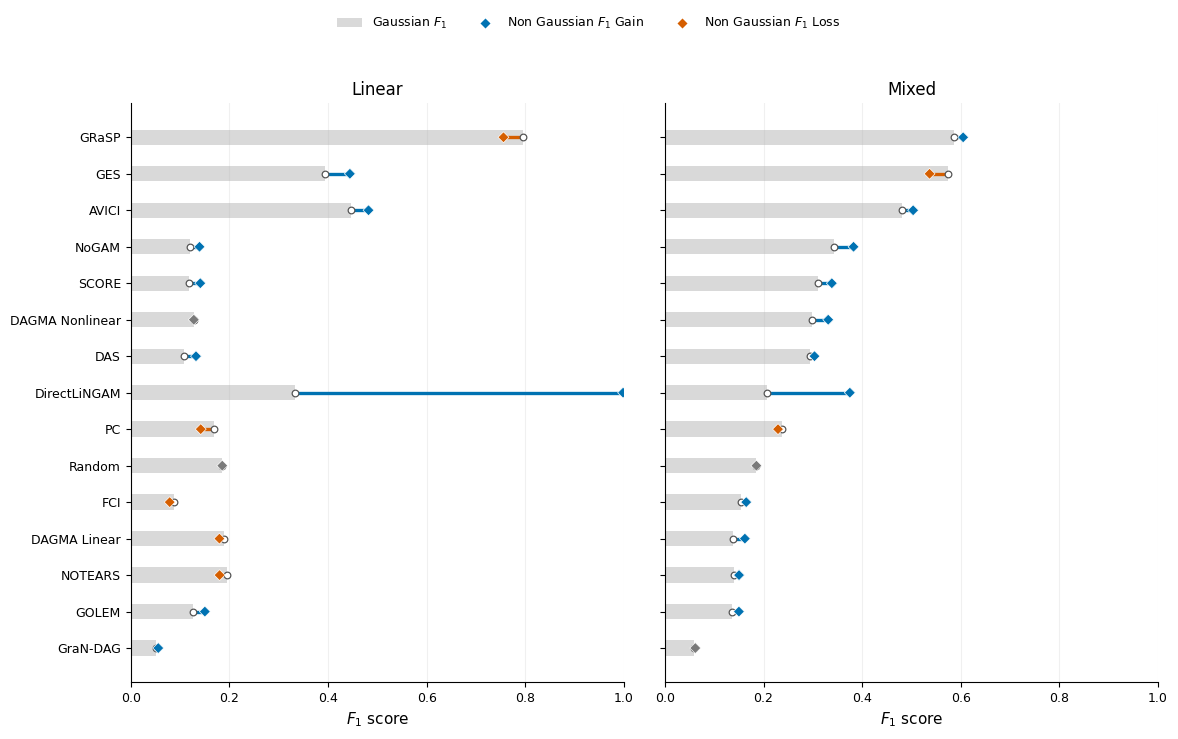

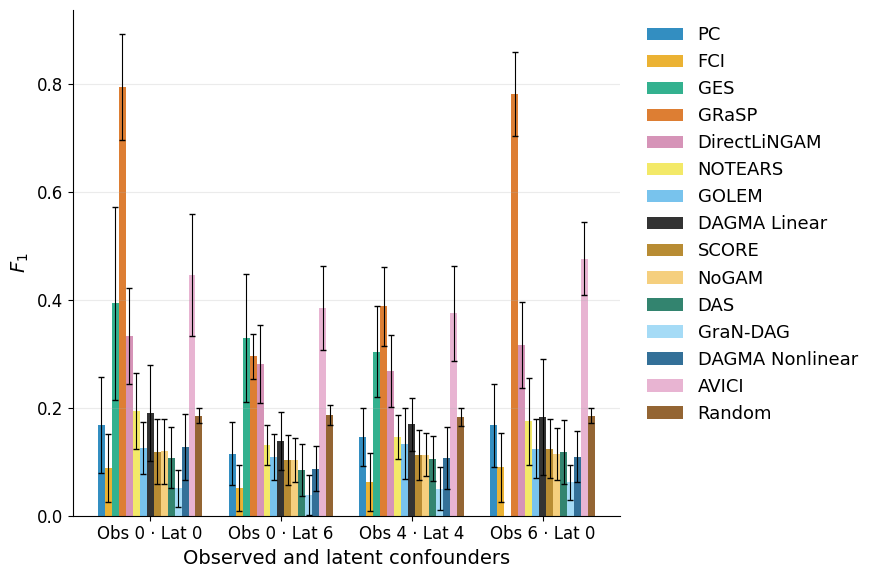

In [4]:
non_gaussian_pdf = th.save_pdf(fig_non_gaussian, "Noise_change_NonGaussian_F1.pdf")
display(fig_non_gaussian)
plt.close(fig_non_gaussian)
fig_conf, _, confounding_output = fv.plot_confounding_f1(
    benchmark_data,
    metric="f1",
    uncertainty="sd",
    n_nodes=20,
    obs_conf=None,
    lat_conf=None,
    coverage_policy="complete",
    bar_alpha=0.8,
    show_metric_title=False,
)
confounding_pdf = th.save_pdf(fig_conf, "Confounders_F1.pdf")
display(fig_conf)
plt.close(fig_conf)
